# Multi-Drone Flood Search: RL Agents, MCTS and Greedy

This notebook compares the search methods of the project on the same seeds:

| Group | Method | Where it lives |
|---|---|---|
| Hand baselines | lawnmower, greedy, look-ahead planner | `sar/baselines/policies.py`, `sar/search/policies_v2.py` |
| RL agents (MAPPO) | `ft_best` (general agent), `ft_flood` (flood agent) | `sar/train/train.py`, `models/mappo_general`, `models/mappo_flood` |
| Tree search | MCTS (Gumbel MuZero) with a hand prior or with the expert-iteration network | `sar/search/mcts.py`, `models/expert_iteration` |
| RL agent (expert iteration) | `rl_search`: the `v2_m4` policy network alone | `sar/train/expert_v2.py` |

It then shows how the agents were trained, from the training logs.

Everything runs on a laptop CPU. Run it from the project root:

```bash
uv run --with matplotlib --with pandas --with jupyterlab jupyter lab notebooks/search_agents.ipynb
```

Sections:
1. Configuration
2. The environment and the flood prior
3. Methods
4. Evaluation of the RL agents against the baselines (env v1, flood maps)
5. One episode, step by step
6. MCTS against greedy and the learned network (env v2)
7. How the agents were trained
8. Summary

## 1. Configuration

In [1]:
import os
from pathlib import Path

# Find the project root (the folder with pyproject.toml) and work from there.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
os.environ.setdefault("JAX_PLATFORMS", "cpu")

SEED = 12345                 # episode keys; every method sees the same maps
LABEL = {"lawnmower": "Lawnmower", "greedy": "Greedy", "planner": "Look-ahead planner",
         "ft_best": "Real-terrain agent (RL)", "ft_flood": "Flood agent (RL)",
         "flood_heldout": "Unseen flood towns", "scene": "3D flood town"}   # plot names
GRID = 64                    # env v1 grid side in cells (30 m cells, 1.92 km)
T_TURN = 1.02                # seconds per 45 degree turn (PX4 calibrated)
N_EPISODES = 200             # env v1 episodes per method and map set
N_EPISODES_V2 = 32           # env v2 episodes per method (MCTS is slower)
GRID_V2 = 32
SIMS = 16                    # MCTS simulations per decision

FLOOD_HELDOUT = ROOT / "data/regions/flood_heldout.npz"   # 200 synthetic flood towns, not used in training
FLOOD_SCENE = ROOT / "data/regions/flooduav_scene.npz"    # prior of the FloodUAV Unity scene
ACTORS = {
    "ft_best": ROOT / "models/mappo_general/seed1/g64_ppo_actor.msgpack",
    "ft_flood": ROOT / "models/mappo_flood/seed1/g64_ppo_actor.msgpack",
}
V2_CKPT = ROOT / "models/expert_iteration/final"
LOGS = ROOT / "notebooks/logs"
print("project root:", ROOT)

project root: <project root>


In [2]:
import json
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from flax import serialization
from tqdm.auto import tqdm

from sar.baselines.policies import POLICIES
from sar.env import maps
from sar.eval.tier0 import GAMMA, make_eval_env, rl_policy, run_episodes
from sar.train.networks import Actor

np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("JAX", jax.__version__, jax.devices())

JAX 0.12.0.1 [CpuDevice(id=0)]


<project root>/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. The Environment and the Flood Prior

The search area is a grid of 30 m cells inside a random polygon. Each cell holds the expected number of
survivors that are still undetected (the **belief**). At the start the belief is the **prior** times the
number of survivors (1 to 10).

- Up to 3 drones decide together, one segment each per decision.
- A look at a cell finds a survivor there with probability `pd` (0.6 to 0.95 per episode), so the belief
  in that cell is multiplied by `1 - pd`.
- **Reward** = expected survivors found by this decision / expected survivors at the start. The sum over an
  episode is the expected fraction found, so it lies in [0, 1].
- The episode ends after 256 decisions, when all drones have left (battery or recall), or when 98% of the
  belief is gone. The score we report is the **discounted return** with gamma 0.995, which rewards finding
  people early.
- **Recall** setting: drones are recalled mid-mission and others join late, as a real fleet would.

The flood prior comes from synthetic river towns: roofs 50%, high ground 25%, bridges 10%, water 10%,
random 5%, with the shares jittered per map.

In [3]:
heldout = np.load(FLOOD_HELDOUT)
scene = np.load(FLOOD_SCENE)
print("held-out bank:", {k: heldout[k].shape for k in heldout.files})
print("scene:", {k: scene[k].shape for k in scene.files})

held-out bank: {'prior': (200, 192, 192), 'ipp_rc': (200, 2)}
scene: {'prior': (1, 64, 64), 'ipp_rc': (1, 2)}


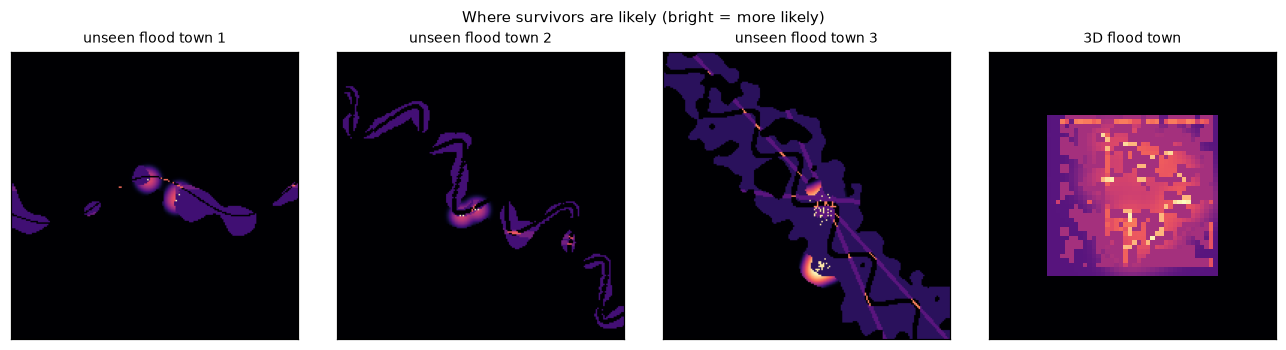

In [4]:
def show_prior(ax, p, title):
    p = np.asarray(p, float)
    ax.imshow(np.log10(p + p.max() * 1e-4), cmap="magma")
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

key = "prior" if "prior" in heldout.files else heldout.files[0]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for i, ax in enumerate(axes[:3]):
    show_prior(ax, heldout[key][i], f"unseen flood town {i + 1}")
skey = "prior" if "prior" in scene.files else scene.files[0]
show_prior(axes[3], np.squeeze(scene[skey]), "3D flood town")
fig.suptitle("Where survivors are likely (bright = more likely)", fontsize=10)
plt.tight_layout(); plt.show()

**Action space.** Each decision a drone flies a 4-move segment to one of the 32 cells on the ring at
Chebyshev distance 4, or holds (33 actions). It looks at every cell it passes. Moves that leave the
polygon or come too close to another drone are masked out. Turns cost time (1.02 s per 45 degrees), and the
battery (1500 s) forces a return home.

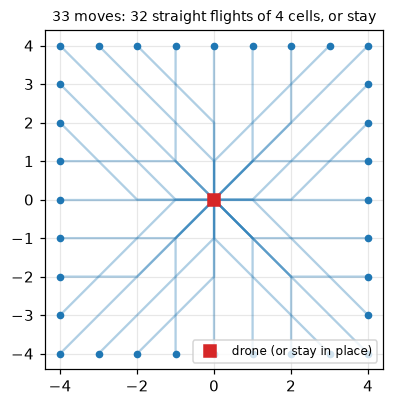

In [5]:
env0 = make_eval_env(GRID, 4, (maps.REAL_KIND,), False, (str(FLOOD_HELDOUT),), T_TURN)
off = np.asarray(env0.offsets)
fig, ax = plt.subplots(figsize=(4, 4))
for a in range(env0.n_actions - 1):
    path = np.vstack([[0, 0], off[a]])
    ax.plot(path[:, 1], -path[:, 0], "-", color="tab:blue", alpha=0.35)
    ax.plot(off[a, -1, 1], -off[a, -1, 0], "o", color="tab:blue", ms=4)
ax.plot(0, 0, "s", color="tab:red", ms=8, label="drone (or stay in place)")
ax.set_aspect("equal"); ax.set_title(f"{env0.n_actions} moves: 32 straight flights of 4 cells, or stay", fontsize=9)
ax.legend(fontsize=8, loc="lower right"); plt.show()

## 3. Methods

**Lawnmower.** Back-and-forth rows inside one column strip per drone; strips are re-split when the fleet
changes. It ignores the prior.

**Greedy.** Each drone takes the segment with the highest immediate expected detections,
`sum over cells of belief * pd`, plus a small pull toward far belief mass to break ties when nothing is
close.

**Look-ahead planner.** Two segments deep: value of segment 1 plus 0.5 times the best segment 2, with the
cells of segment 1 discounted in segment 2. Drones plan in turn on a shared belief copy, so they do not
search the same cells. It is also the **teacher** for behaviour cloning.

**RL agents (MAPPO).** One actor network shared by all drones (decentralised execution) and a centralised
critic that sees a 32 x 32 map of the whole area (centralised training). Inputs per drone:

| Input | Shape | Content |
|---|---|---|
| local crop | 31 x 31 x 4 | belief, polygon, look counts, other drones and their segments |
| global view | 32 x 32 x 3 | pooled belief, polygon, other drones, centred on the drone |
| scalars | 12 | battery, return time, time left, belief left, fleet size, pd, position, home |

The actor outputs 33 logits; masked actions get -1e9. We act with argmax at evaluation.

**MCTS.** Gumbel MuZero search (`mctx`) on the true env model (env v2). Every drone runs its own tree row;
at a node the deciding drone takes the tree action and the others take a default action. Prior and value
come either from a hand function (greedy score plus a 4-step greedy rollout) or from the `v2_m4` network.

In [6]:
def load_actor(path):
    actor = Actor(env0.n_actions)
    _, obs = env0.reset(jax.random.PRNGKey(0))
    tmpl = actor.init(jax.random.PRNGKey(0), obs["local"], obs["global"], obs["scalars"], obs["action_mask"])
    params = serialization.from_bytes(tmpl, Path(path).read_bytes())
    n = sum(x.size for x in jax.tree_util.tree_leaves(params))
    print(f"{Path(path).parent.parent.name}: {n:,} actor parameters")
    return rl_policy(actor, params)

METHODS = {"lawnmower": POLICIES["lawnmower"], "greedy": POLICIES["greedy"], "planner": POLICIES["planner"]}
for name, path in ACTORS.items():
    METHODS[name] = load_actor(path)

ft_best: 1,478,465 actor parameters
ft_flood: 1,478,465 actor parameters


## 4. Evaluation: RL Agents Against the Baselines

Tier 0 protocol: every method runs on the same episode keys (paired comparison), at grid 64, on two map
sets that were **not** used in training:

- `flood_heldout`: 200 synthetic flood towns from a different generator seed.
- `scene`: the prior of the FloodUAV Unity town, where the GUI flies.

Metrics: discounted return (main score), fraction found by the end, and the number of decisions to find 50%
and 90% of the expected survivors (256 = not reached).

In [7]:
MAPSETS = {"flood_heldout": FLOOD_HELDOUT, "scene": FLOOD_SCENE}
keys = jax.random.split(jax.random.PRNGKey(SEED), N_EPISODES)
per_ep, rows = {}, []
jobs = [(m, r, n) for m in MAPSETS for r in (False, True) for n in METHODS]
t0 = time.time()
for mapset, recall, name in tqdm(jobs, desc="Tier 0"):
    env = make_eval_env(GRID, 4, (maps.REAL_KIND,), recall, (str(MAPSETS[mapset]),), T_TURN)
    m = {k: np.asarray(v) for k, v in run_episodes(env, METHODS[name], keys).items()}
    per_ep[(mapset, recall, name)] = m
    rows.append({"mapset": mapset, "recall": recall, "method": name,
                 "disc_return": m["disc_return"].mean(),
                 "se": m["disc_return"].std() / np.sqrt(N_EPISODES),
                 "found": m["found"].mean(), "t50": m["t50"].mean(), "t90": m["t90"].mean()})
print(f"{len(jobs)} runs of {N_EPISODES} episodes in {time.time() - t0:.0f} s")
tier0 = pd.DataFrame(rows)
tier0.round(3)

Tier 0:   0%|          | 0/20 [00:00<?, ?it/s]

Tier 0:   5%|▌         | 1/20 [00:04<01:29,  4.71s/it]

Tier 0:  10%|█         | 2/20 [00:10<01:32,  5.13s/it]

Tier 0:  15%|█▌        | 3/20 [00:18<01:49,  6.41s/it]

Tier 0:  20%|██        | 4/20 [00:24<01:44,  6.50s/it]

Tier 0:  25%|██▌       | 5/20 [00:31<01:38,  6.57s/it]

... (14 outputs left out)

Tier 0: 100%|██████████| 20/20 [02:07<00:00,  6.76s/it]

Tier 0: 100%|██████████| 20/20 [02:07<00:00,  6.36s/it]

20 runs of 200 episodes in 127 s


,mapset,recall,method,disc_return,se,found,t50,t90
0,flood_heldout,False,lawnmower,0.502,0.013,0.593,114.010002,245.399994
1,flood_heldout,False,greedy,0.713,0.008,0.788,24.084999,218.240005
2,flood_heldout,False,planner,0.705,0.008,0.779,28.350000,219.255005
3,flood_heldout,False,ft_best,0.714,0.008,0.806,28.520000,206.639999
4,flood_heldout,False,ft_flood,0.726,0.007,0.818,26.924999,202.630005
5,flood_heldout,True,lawnmower,0.408,0.013,0.506,158.789993,251.919998
6,flood_heldout,True,greedy,0.642,0.009,0.731,43.990002,239.445007
7,flood_heldout,True,planner,0.649,0.009,0.736,40.820000,237.759995
8,flood_heldout,True,ft_best,0.635,0.009,0.737,49.689999,234.940002
9,flood_heldout,True,ft_flood,0.643,0.009,0.745,47.915001,231.399994


In [8]:
# Discounted return per cell (rows: map set and recall, columns: method)
pivot = tier0.pivot_table(index=["mapset", "recall"], columns="method", values="disc_return")[list(METHODS)]
pivot.style.format("{:.3f}").highlight_max(axis=1, props="font-weight: bold")

In [9]:
# Paired difference against greedy: mean and 95% CI of (method - greedy) over the same episodes
diff_rows = []
for (mapset, recall, name), m in per_ep.items():
    if name == "greedy":
        continue
    d = m["disc_return"] - per_ep[(mapset, recall, "greedy")]["disc_return"]
    h = 1.96 * d.std() / np.sqrt(len(d))
    diff_rows.append({"mapset": mapset, "recall": recall, "method": name,
                      "vs greedy": f"{d.mean():+.4f} [{d.mean() - h:+.4f}, {d.mean() + h:+.4f}]"})
pd.DataFrame(diff_rows).pivot_table(index=["mapset", "recall"], columns="method",
                                    values="vs greedy", aggfunc="first")

method                                   ft_best                    ft_flood  \
mapset        recall                                                           
flood_heldout False   +0.0013 [-0.0022, +0.0048]  +0.0130 [+0.0099, +0.0160]   
              True    -0.0066 [-0.0104, -0.0028]  +0.0009 [-0.0024, +0.0043]   
scene         False   +0.0112 [+0.0088, +0.0137]  +0.0179 [+0.0155, +0.0202]   
              True    +0.0006 [-0.0023, +0.0035]  +0.0055 [+0.0027, +0.0084]   

method                                 lawnmower                     planner  
mapset        recall                                                          
flood_heldout False   -0.2111 [-0.2297, -0.1926]  -0.0076 [-0.0169, +0.0018]  
              True    -0.2338 [-0.2527, -0.2150]  +0.0071 [+0.0040, +0.0101]  
scene         False   -0.1789 [-0.1921, -0.1658]  -0.0378 [-0.0560, -0.0197]  
              True    -0.1957 [-0.2090, -0.1825]  -0.0049 [-0.0139, +0.0041]

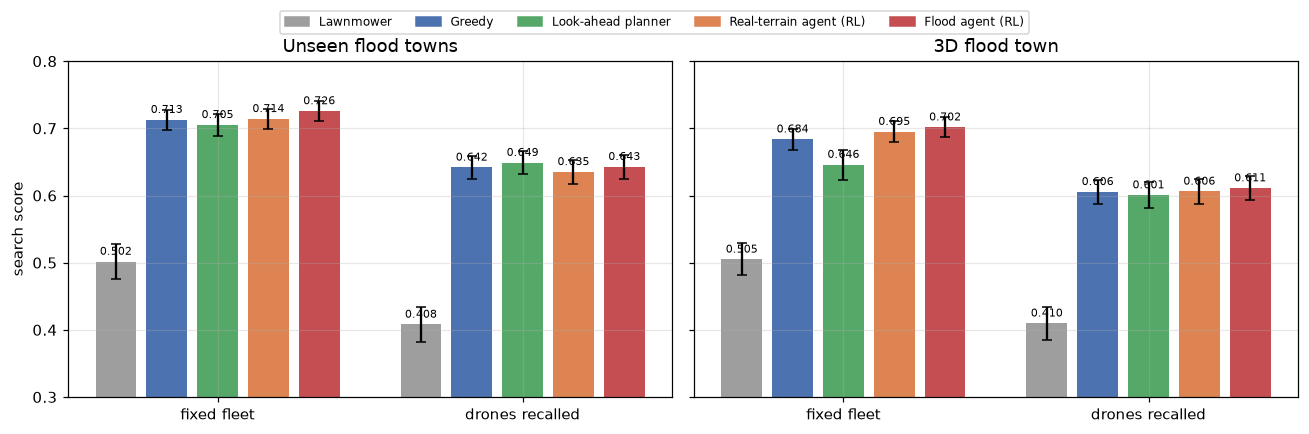

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
colors = {"lawnmower": "#9e9e9e", "greedy": "#4c72b0", "planner": "#55a868", "ft_best": "#dd8452", "ft_flood": "#c44e52"}
for ax, mapset in zip(axes, MAPSETS):
    sub = tier0[tier0.mapset == mapset]
    for j, recall in enumerate((False, True)):
        s = sub[sub.recall == recall].set_index("method").loc[list(METHODS)]
        x = np.arange(len(s)) + j * (len(s) + 1)
        ax.bar(x, s.disc_return, yerr=1.96 * s.se, color=[colors[m] for m in s.index], capsize=3)
        for xi, v in zip(x, s.disc_return):
            ax.text(xi, v + 0.01, f"{v:.3f}", ha="center", fontsize=7)
    ax.set_xticks([2, 8]); ax.set_xticklabels(["fixed fleet", "drones recalled"])
    ax.set_title(LABEL[mapset]); ax.set_ylim(0.3, 0.8)
axes[0].set_ylabel("search score")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
fig.legend(handles, [LABEL[m] for m in colors], loc="upper center", ncol=5, fontsize=8, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout(); plt.show()

## 5. One Episode, Step by Step

The same flood map flown by greedy and by `ft_flood`. Left: drone paths over the prior. Right: expected
fraction of survivors found against the number of decisions.

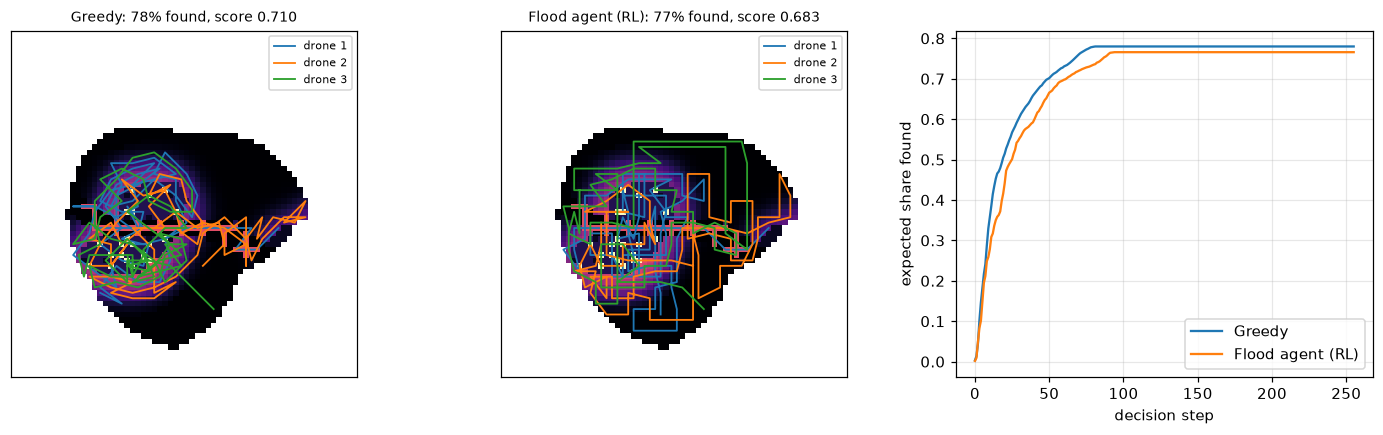

In [11]:
def trace(env, policy, key, steps=None):
    # One episode: positions [T, N, 2], status [T, N] and rewards [T].
    T = steps or env.cfg.max_steps
    k1, k2 = jax.random.split(key)
    s, _ = env.reset(k1)

    def body(c, _):
        s, done, k = c
        k, ka = jax.random.split(k)
        s2, _, r, d = env.step(s, policy(env, s, ka))
        return (s2, done | d, k), (s.pos, s.status, jnp.where(done, 0.0, r))

    (sT, _, _), (pos, status, rew) = jax.jit(lambda s, k: jax.lax.scan(body, (s, jnp.array(False), k), None, T))(s, k2)
    return s, np.asarray(pos), np.asarray(status), np.asarray(rew)

env_vis = make_eval_env(GRID, 4, (maps.REAL_KIND,), False, (str(FLOOD_HELDOUT),), T_TURN)
ep_key = jax.random.PRNGKey(7)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name in zip(axes[:2], ("greedy", "ft_flood")):
    s0, pos, status, rew = trace(env_vis, METHODS[name], ep_key)
    b = np.where(np.asarray(s0.mask), np.asarray(s0.belief), np.nan)
    ax.imshow(np.log10(b + np.nanmax(b) * 1e-4), cmap="magma")
    for i in range(env_vis.n):
        on = status[:, i] == 1
        if on.any():
            ax.plot(pos[on, i, 1], pos[on, i, 0], "-", lw=1.2, label=f"drone {i + 1}")
    ax.set_title(f"{LABEL[name]}: {rew.sum():.0%} found, score {np.sum(rew * GAMMA ** np.arange(len(rew))):.3f}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.legend(fontsize=7)
    axes[2].plot(np.cumsum(rew), label=LABEL[name])
axes[2].set_xlabel("decision step"); axes[2].set_ylabel("expected share found"); axes[2].legend()
plt.tight_layout(); plt.show()

## 6. MCTS Against Greedy and the Learned Network (env v2)

Env v2 adds two altitude levels (low: 1 cell footprint; high: 3 x 3 cells with lower `pd`), per-cell `pd`
from land cover and canopy, and battery sorties with a 180 s swap. It has 66 actions (33 per level).
MCTS is built for env v2, so this section compares on env v2, held-out prior type (random blobs),
recall off.

| Method | Prior | Value | Search |
|---|---|---|---|
| greedy | - | - | none |
| planner | - | - | two-segment look-ahead |
| `rl_search` | `v2_m4` network | - | none (argmax of the network) |
| `mcts_hand` | greedy score | greedy score + 4-step greedy rollout | Gumbel MuZero, fleet search |
| `mcts_net` | `v2_m4` network | `v2_m4` network | Gumbel MuZero, fleet search |

In [12]:
from sar.config_v2 import TrainConfigV2
from sar.search import mcts, policies_v2 as P2
from sar.train import networks_v2 as NN2
from sar.train.expert_v2 import load_ckpt, make_env as make_env_v2

env2 = make_env_v2(GRID_V2, kinds=(3,), p_leave=0.0, p_join=0.0)
net, net_params, meta = load_ckpt(V2_CKPT, dtype=jnp.float32)
tcfg = TrainConfigV2(search_depth=8, max_considered=16)
hand_search = mcts.make_fleet_search_fn(env2, tcfg, net=None, rollout_depth=4)
net_search = mcts.make_fleet_search_fn(env2, tcfg, net=net, value_scale=meta["value_scale"])

def net_act(env, s, k):
    obs = env.observe(s)
    obs["gain"] = P2.action_gain(env, s)
    logits, _ = NN2.apply_obs(net, net_params, obs)
    return jnp.argmax(logits, -1)

def mcts_hand(sims):
    return lambda env, s, k: hand_search(None, s, k, sims, 0.0).action

def mcts_net(sims):
    return lambda env, s, k: net_search(net_params, s, k, sims, 0.0).action

V2_METHODS = {
    "greedy": P2.greedy, "planner": P2.lookahead, "rl_search": net_act,
    f"mcts_hand_{SIMS}": mcts_hand(SIMS), f"mcts_net_{SIMS}": mcts_net(SIMS),
}
print(f"env v2: grid {GRID_V2}, {env2.n_actions} actions, network trained on {meta['samples']:,} samples")

env v2: grid 32, 66 actions, network trained on 202,967 samples


In [13]:
keys2 = jax.random.split(jax.random.PRNGKey(SEED + 1), N_EPISODES_V2)
v2_ep, v2_rows = {}, []
for name, pol in tqdm(V2_METHODS.items(), desc="env v2"):
    t0 = time.time()
    m = {k: np.asarray(v) for k, v in run_episodes(env2, pol, keys2).items()}
    v2_ep[name] = m
    v2_rows.append({"method": name, "disc_return": m["disc_return"].mean(),
                    "se": m["disc_return"].std() / np.sqrt(N_EPISODES_V2),
                    "found": m["found"].mean(), "seconds": time.time() - t0})
v2 = pd.DataFrame(v2_rows)
g = v2_ep["greedy"]["disc_return"]
v2["vs greedy"] = [f"{(v2_ep[n]['disc_return'] - g).mean():+.4f} ± {1.96 * (v2_ep[n]['disc_return'] - g).std() / np.sqrt(len(g)):.4f}"
                   for n in v2.method]
v2.round(4)

env v2:   0%|          | 0/5 [00:00<?, ?it/s]

env v2:  20%|██        | 1/5 [00:01<00:04,  1.13s/it]

env v2:  40%|████      | 2/5 [00:06<00:11,  3.81s/it]

env v2:  60%|██████    | 3/5 [00:08<00:05,  2.81s/it]

env v2:  80%|████████  | 4/5 [00:38<00:13, 13.41s/it]

env v2: 100%|██████████| 5/5 [01:08<00:00, 19.68s/it]

env v2: 100%|██████████| 5/5 [01:08<00:00, 13.78s/it]

,method,disc_return,se,found,seconds,vs greedy
0,greedy,0.9174,0.0071,0.9775,1.1293,+0.0000 ± 0.0000
1,planner,0.9296,0.0048,0.9776,5.6858,+0.0123 ± 0.0078
2,rl_search,0.9150,0.0089,0.9763,1.6130,-0.0023 ± 0.0095
3,mcts_hand_16,0.9190,0.0061,0.9764,29.6635,+0.0017 ± 0.0107
4,mcts_net_16,0.9189,0.0078,0.9755,30.7837,+0.0015 ± 0.0037


**Simulation budget.** With one simulation the search can only expand the top prior action, so it equals
greedy (a test in `tests/test_mcts.py` checks this). More simulations let it deviate from greedy.

MCTS sims:   0%|          | 0/4 [00:00<?, ?it/s]

MCTS sims:  25%|██▌       | 1/4 [00:05<00:15,  5.00s/it]

MCTS sims:  50%|█████     | 2/4 [00:15<00:16,  8.05s/it]

MCTS sims:  75%|███████▌  | 3/4 [00:44<00:17, 17.81s/it]

MCTS sims: 100%|██████████| 4/4 [01:42<00:00, 33.71s/it]

MCTS sims: 100%|██████████| 4/4 [01:42<00:00, 25.67s/it]

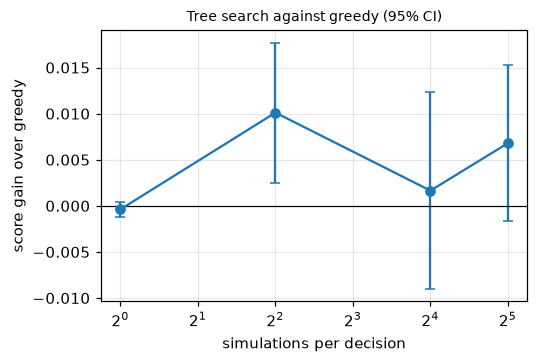

,sims,disc_return,vs greedy,ci
0,1,0.9170,-0.0004,0.0008
1,4,0.9275,0.0101,0.0076
2,16,0.9190,0.0017,0.0107
3,32,0.9242,0.0068,0.0085


In [14]:
sweep = []
for sims in tqdm((1, 4, 16, 32), desc="MCTS sims"):
    m = run_episodes(env2, mcts_hand(sims), keys2)
    d = np.asarray(m["disc_return"]) - g
    sweep.append({"sims": sims, "disc_return": float(np.mean(m["disc_return"])),
                  "vs greedy": d.mean(), "ci": 1.96 * d.std() / np.sqrt(len(d))})
sweep = pd.DataFrame(sweep)
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.errorbar(sweep.sims, sweep["vs greedy"], yerr=sweep.ci, marker="o", capsize=3)
ax.axhline(0, color="k", lw=0.8); ax.set_xscale("log", base=2)
ax.set_xlabel("simulations per decision"); ax.set_ylabel("score gain over greedy")
ax.set_title("Tree search against greedy (95% CI)", fontsize=9); plt.show()
sweep.round(4)

## 7. How the Agents Were Trained

### 7.1 MAPPO with behaviour cloning (`sar/train/train.py`)

All environments run on the GPU in JAX (`jax.vmap` over 512 envs, `jax.lax.scan` over 64 steps), about
16,500 env steps per second per RTX 3060 at grid 96.

1. **Behaviour cloning (DAgger).** The look-ahead planner labels every state. The student's own action is
   executed in a growing share of envs (up to 50%), so it also learns to recover from its own mistakes.
   Loss: cross entropy to the planner's action.
2. **MAPPO.** Clipped PPO (clip 0.2, GAE lambda 0.95, gamma 0.995, entropy 0.003) with a shared actor and a
   centralised critic. The critic trains alone for the first 50 updates. A KL penalty to the cloned policy
   (weight 0.5) fades to 0 over 800 updates, so PPO starts from the planner and does not forget it early.
3. **Curriculum over map size.** Grids 32, 64, 96 (polygons of 16-30, 30-60, 50-94 cells). Network shapes do
   not change between stages, so the weights carry over.

| Agent | Start | Data | Updates | Notes |
|---|---|---|---|---|
| `main_r4` | scratch | synthetic priors (rings, lines) | BC 100/100/800 + PPO 200/300/1800 at g32/g64/g96 | 130 min on one GPU |
| `ft_best` | `main_r4` | 50% real region-bank priors, turn time 1.02 s | 2000 PPO updates, lr 1e-4, no BC | 119 min |
| `ft_flood` | `ft_best` | 5 of 8 maps from the flood training bank (600 towns), 3 of 8 synthetic | PPO at g32, g96, g64, lr 5e-5 | best of 2 seeds on flood maps |

### 7.2 Expert iteration for env v2 (`sar/train/expert_v2.py`)

1. Round 0: roll out the planner on 3072 episodes, store observations and its actions, fit the
   policy-value network (cross entropy to the action, squared error to the Monte Carlo return).
2. Rounds 1-4: roll out the network-guided MCTS (32 simulations), store the Gumbel MuZero improved policy as
   the target, retrain on all data. The final network (`v2_m4`) is round 3.

### 7.3 Training curves of `main_r4` (seed 1)

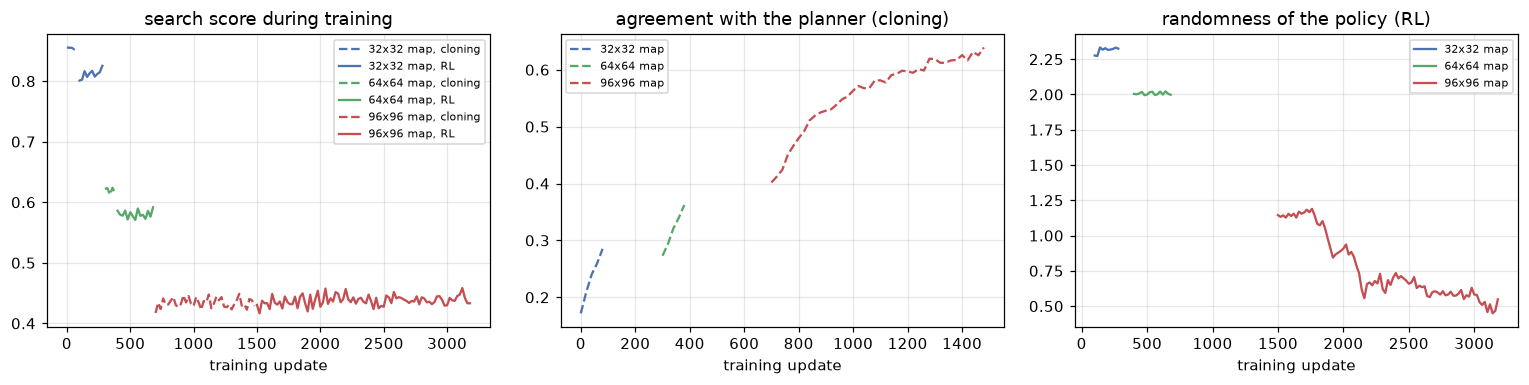

training time 130 min, mean 14,356 env steps/s


In [15]:
log = pd.DataFrame([json.loads(l) for l in open(LOGS / "main_r4_metrics_seed1.jsonl")])
for c in ("ep_disc", "bc_acc", "entropy", "kl_bc", "v_loss"):
    if c in log:
        log[c] = log[c].map(lambda v: v[0] if isinstance(v, list) else v)
log["step"] = np.arange(len(log)) * 20          # one record per chunk of 20 updates

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
stage_col = {32: "#4c72b0", 64: "#55a868", 96: "#c44e52"}
for (gsz, mode), part in log.groupby(["grid", "mode"], sort=False):
    ls = "--" if mode == "bc" else "-"
    axes[0].plot(part.step, part.ep_disc, ls, color=stage_col[gsz], label=f"{gsz}x{gsz} map, {'cloning' if mode == 'bc' else 'RL'}")
    if mode == "bc":
        axes[1].plot(part.step, part.bc_acc, ls, color=stage_col[gsz], label=f"{gsz}x{gsz} map")
    else:
        axes[2].plot(part.step, part.entropy, color=stage_col[gsz], label=f"{gsz}x{gsz} map")
axes[0].set_title("search score during training"); axes[0].legend(fontsize=7)
axes[1].set_title("agreement with the planner (cloning)"); axes[1].legend(fontsize=7)
axes[2].set_title("randomness of the policy (RL)"); axes[2].legend(fontsize=7)
for ax in axes:
    ax.set_xlabel("training update")
plt.tight_layout(); plt.show()
print(f"training time {log.minutes.iloc[-1]:.0f} min, mean {log.sps.mean():,.0f} env steps/s")

The return drops at each stage change because larger maps are harder (a fixed 256 decisions cover less of
the area), not because the policy got worse. Cloning accuracy rises at every stage; PPO entropy falls as
the policy commits.

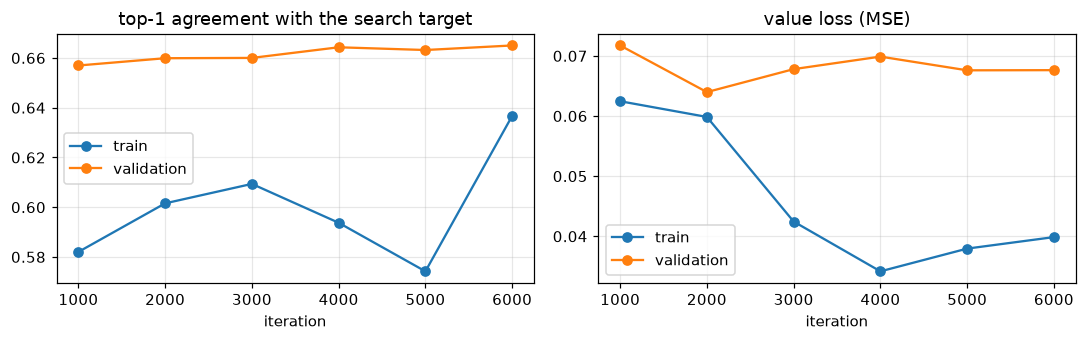

{'samples': 202967, 'iters': 6000, 'batch': 256, 'lr': 0.0002, 'width': 64, 'embed': 256}


In [16]:
meta_log = json.load(open(LOGS / "v2_m4_meta.json"))
h = pd.DataFrame(meta_log["history"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(h.iter, h.train_acc, "o-", label="train"); axes[0].plot(h.iter, h.val_acc, "o-", label="validation")
axes[0].set_title("top-1 agreement with the search target"); axes[0].legend()
axes[1].plot(h.iter, h.train_val, "o-", label="train"); axes[1].plot(h.iter, h.val_val, "o-", label="validation")
axes[1].set_title("value loss (MSE)"); axes[1].legend()
for ax in axes:
    ax.set_xlabel("iteration")
plt.tight_layout(); plt.show()
print({k: meta_log[k] for k in ("samples", "iters", "batch", "lr", "width", "embed")})

### 7.4 Commands

```bash
# MAPPO from scratch with cloning (GPU machine, one process per GPU)
uv run python -m sar.train.train --name main_r4 --seed 1 --n-envs 512 --grids 32,64,96 \
    --bc-iters 100,100,800 --ppo-updates 200,300,1800 --ppo-epochs 2 --minibatches 4 \
    --bc-epochs 4 --kl-fade 800 --chunk 20 --max-minutes 130

# Flood fine-tune from ft_best (prior kind 4 = flood bank, weighted 5 of 8)
uv run python -m sar.train.train --name ft_flood --seed 3 --n-envs 512 --grids 32,96,64 \
    --bc-iters 0,0,0 --init-dir <ft_best run dir> --lr 5e-5 --t-turn 1.02 \
    --prior-kinds 0,1,2,4,4,4,4,4 --real-bank data/regions/flood_train.npz --save-every 15

# Expert iteration (env v2)
uv run python -m sar.train.expert_v2 gen --policy planner --episodes 3072 --out runs/v2/m4_data/r0
uv run python -m sar.train.expert_v2 train --data runs/v2/m4_data/r0 --gain --out runs/v2/m4_ckpt/r0
uv run python -m sar.train.expert_v2 gen --policy search --ckpt runs/v2/m4_ckpt/r0 --sims 32 --out runs/v2/m4_data/r1

# Tier 0 evaluation (1000 episodes, as reported)
uv run python -m sar.eval.tier0 --grid 64 --episodes 1000 --t-turn 1.02 --mapsets real_heldout \
    --real-heldout data/regions/flood_heldout.npz --actor ft_flood=models/mappo_flood/seed1/g64_ppo_actor.msgpack
```

## 8. Summary

In [17]:
best = tier0.loc[tier0.groupby(["mapset", "recall"]).disc_return.idxmax(), ["mapset", "recall", "method", "disc_return"]]
print("Best method per env v1 cell:")
print(best.to_string(index=False))
print("\nEnv v2:")
print(v2[["method", "disc_return", "vs greedy"]].to_string(index=False))

Best method per env v1 cell:
       mapset  recall   method  disc_return
flood_heldout   False ft_flood     0.725841
flood_heldout    True  planner     0.648934
        scene   False ft_flood     0.701733
        scene    True ft_flood     0.611080

Env v2:
      method  disc_return        vs greedy
      greedy     0.917374 +0.0000 ± 0.0000
     planner     0.929631 +0.0123 ± 0.0078
   rl_search     0.915038 -0.0023 ± 0.0095
mcts_hand_16     0.919025 +0.0017 ± 0.0107
 mcts_net_16     0.918865 +0.0015 ± 0.0037


- The RL agents learn a search that matches or beats the hand baselines on flood maps they never saw, and
  the flood fine-tune (`ft_flood`) gains most on the flood map sets.
- Lawnmower is far behind: covering every cell evenly wastes time in empty water.
- Greedy is a strong baseline for this problem, because the reward is an expected detection that greedy
  maximises one step at a time.
- MCTS with the hand prior is level with the look-ahead planner; the learned network did not improve the
  search, because its value error is larger than the gap between sibling actions.
- Numbers here use fewer episodes than the 1000-episode results in the report, so their CIs are wider.